# Citi Bike Trip Data: 16 Pandas Exercises (with Solutions)

**Dataset:** [Official NYC Citi Bike Trip Histories](https://citibikenyc.com/system-data) · [Monthly CSV archives](https://s3.amazonaws.com/tripdata/index.html)

This notebook uses the **modern 13-column trip schema** (ride_id, rideable_type, started_at, ended_at, start/end station IDs and names, coordinates, and member_casual). Download **one NYC month** (not a Jersey City archive prefixed `JC`) and place its `.zip` archive or extracted `.csv` file(s) in a `data/` folder next to this notebook. One monthly ZIP can contain multiple CSVs, which will all be read.

Run cells top to bottom. Each question has a worked Python solution directly beneath it. Visualizations use **Matplotlib** and **Plotly**. The data are not included with this notebook, so results will depend on the chosen month.

**Teaching note:** To turn this into a student assignment, hide/remove solution code cells and retain the Markdown questions.

## Setup: Install packages and load one month's data

Create `data/` and place one modern Citi Bike monthly `.zip` archive **or** its extracted `.csv` files there. If using extracted files, avoid mixing months unless deliberately performing a multi-month analysis. The cell detects input automatically. If memory is limited, set `MAX_ROWS` to an integer (for example `300_000`), but this reads the first rows rather than a representative random sample and may bias time-of-day findings.

In [1]:
# Uncomment once if needed:
# %pip install pandas numpy matplotlib plotly

from pathlib import Path
from zipfile import ZipFile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

DATA_DIR = Path("data")
MAX_ROWS = None  # None = full dataset; integer = first N rows (nonrandom sample)

zip_files = sorted(DATA_DIR.glob("*.zip"))
csv_files = sorted(DATA_DIR.glob("*.csv"))
if zip_files and csv_files:
    raise ValueError("Use ZIP archives OR extracted CSVs in data/, not both (avoid double-counting).")
if not zip_files and not csv_files:
    raise FileNotFoundError("Download a Citi Bike monthly ZIP/CSV and put it in data/.")

pieces = []
if zip_files:
    for archive in zip_files:
        with ZipFile(archive) as z:
            for name in sorted(z.namelist()):
                if name.lower().endswith('.csv') and not name.startswith('__MACOSX'):
                    with z.open(name) as f:
                        pieces.append(pd.read_csv(f, nrows=MAX_ROWS, low_memory=False,
                                                  dtype={'start_station_id':'string', 'end_station_id':'string'}))
else:
    for file in csv_files:
        pieces.append(pd.read_csv(file, nrows=MAX_ROWS, low_memory=False,
                                  dtype={'start_station_id':'string', 'end_station_id':'string'}))

df = pd.concat(pieces, ignore_index=True)
required = {'ride_id','rideable_type','started_at','ended_at','start_station_name',
            'start_station_id','end_station_name','end_station_id',
            'start_lat','start_lng','end_lat','end_lng','member_casual'}
missing_columns = required - set(df.columns)
if missing_columns:
    raise ValueError(f"Not a modern Citi Bike trip file; missing: {sorted(missing_columns)}")

for col in ('started_at','ended_at'):
    df[col] = pd.to_datetime(df[col], errors='coerce')
for col in ('start_lat','start_lng','end_lat','end_lng'):
    df[col] = pd.to_numeric(df[col], errors='coerce')

print(f'{len(df):,} rows from {len(pieces)} CSV file(s)')
print('Date range:', df.started_at.min(), 'to', df.started_at.max())
df.head()

1,219,444 rows from 2 CSV file(s)
Date range: 2026-01-30 23:24:24.773000 to 2026-02-28 23:57:16.242000


,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,8CA3B6A78AF59CA5,electric_bike,2026-02-06 17:20:08.324,2026-02-06 17:24:21.584,Bond St & Bergen St,4404.10,Amity St & Court St,4488.10,40.684967,-73.986208,40.688419,-73.993142,member
1,C6426029C22F971F,electric_bike,2026-02-04 12:02:28.817,2026-02-04 12:10:27.340,Norman Ave & Leonard St,5666.11,Jackson Ave & 49 Ave,6170.09,40.725819,-73.950815,40.742930,-73.952037,member
2,D29833A48B94FDC8,electric_bike,2026-02-11 19:37:21.253,2026-02-11 19:43:18.957,E 2 St & Ave C,5476.03,E 2 St & 2 Ave,5593.02,40.720874,-73.980858,40.725029,-73.990697,member
3,45FCBB4F298A024E,electric_bike,2026-02-01 12:31:54.323,2026-02-01 12:39:24.020,St James Pl & Oliver St,5238.05,E 2 St & 2 Ave,5593.02,40.713079,-73.998512,40.725029,-73.990697,member
4,3E2B396559BECD35,classic_bike,2026-02-13 05:49:37.127,2026-02-13 06:09:27.904,W 20 St & 7 Ave,6182.02,W 13 St & 5 Ave,5947.04,40.742388,-73.997262,40.735445,-73.994310,member


## Exercise 1 — Getting acquainted with the data

1. How many trip records are there? How many unique start stations and end stations?
2. List the observed bike types and rider categories and their counts.
3. Identify missing fields and duplicate `ride_id` values. Which missing data could affect later analyses?

In [2]:
print('Shape:', df.shape)
display(df.info(), df.describe(include='all').T)
print('Unique start stations:', df.start_station_id.nunique())
print('Unique end stations:', df.end_station_id.nunique())
print('Bike types:\n', df.rideable_type.value_counts(dropna=False))
print('Rider categories:\n', df.member_casual.value_counts(dropna=False))
print('Missing values:\n', df.isna().sum().sort_values(ascending=False))
print('Duplicate ride IDs:', df.ride_id.duplicated().sum())

Shape: (1219444, 13)
<class 'pandas.DataFrame'>
RangeIndex: 1219444 entries, 0 to 1219443
Data columns (total 13 columns):
 #   Column              Non-Null Count    Dtype         
---  ------              --------------    -----         
 0   ride_id             1219444 non-null  str           
 1   rideable_type       1219444 non-null  str           
 2   started_at          1219444 non-null  datetime64[us]
 3   ended_at            1219444 non-null  datetime64[us]
 4   start_station_name  1218325 non-null  str           
 5   start_station_id    1218325 non-null  string        
 6   end_station_name    1212787 non-null  str           
 7   end_station_id      1211386 non-null  string        
 8   start_lat           1218325 non-null  float64       
 9   start_lng           1218325 non-null  float64       
 10  end_lat             1211437 non-null  float64       
 11  end_lng             1211437 non-null  float64       
 12  member_casual       1219444 non-null  str           
dtypes:

None

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
ride_id,1219444,1219444,8CA3B6A78AF59CA5,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rideable_type,1219444,2,electric_bike,888383,NaN,NaN,NaN,NaN,NaN,NaN,NaN
started_at,1219444,NaN,NaN,NaN,2026-02-15 21:35:46.810912,2026-01-30 23:24:24.773000,2026-02-10 08:27:13.776250,2026-02-15 18:46:19.371000,2026-02-21 13:03:21.549750,2026-02-28 23:57:16.242000,NaN
ended_at,1219444,NaN,NaN,NaN,2026-02-15 21:47:40.430204,2026-02-01 00:00:13.400000,2026-02-10 08:38:29.281750,2026-02-15 18:56:41.809500,2026-02-21 13:15:58.622000,2026-02-28 23:59:59.946000,NaN
start_station_name,1218325,2211,W 21 St & 6 Ave,5412,NaN,NaN,NaN,NaN,NaN,NaN,NaN
start_station_id,1218325,2214,6140.05,5412,NaN,NaN,NaN,NaN,NaN,NaN,NaN
end_station_name,1212787,2242,Pier 61 at Chelsea Piers,5433,NaN,NaN,NaN,NaN,NaN,NaN,NaN
end_station_id,1211386,2277,6233.04,5433,NaN,NaN,NaN,NaN,NaN,NaN,NaN
start_lat,1218325.0,NaN,NaN,NaN,40.736338,40.61124,40.71323,40.736197,40.759125,40.8863,0.038989
start_lng,1218325.0,NaN,NaN,NaN,-73.972071,-74.04079,-73.9916,-73.979453,-73.955769,-73.84672,0.027755


Unique start stations: 2214
Unique end stations: 2277
Bike types:
 rideable_type
electric_bike    888383
classic_bike     331061
Name: count, dtype: int64
Rider categories:
 member_casual
member    1110817
casual     108627
Name: count, dtype: int64
Missing values:
 end_station_id        8058
end_lat               8007
end_lng               8007
end_station_name      6657
start_station_name    1119
start_lat             1119
start_station_id      1119
start_lng             1119
ride_id                  0
ended_at                 0
started_at               0
rideable_type            0
member_casual            0
dtype: int64
Duplicate ride IDs: 0


### Shared cleaning and derived variables

All subsequent exercises use `rides`: records with valid trip start/end times and **positive durations**. We retain valid but unusually long trips for investigation rather than silently deleting them. Station-based analyses drop missing station IDs only when needed. A weekday is Monday–Friday.

In [3]:
rides = df.drop_duplicates(subset='ride_id').copy()
rides['duration_min'] = (rides.ended_at - rides.started_at).dt.total_seconds() / 60
rides = rides.loc[rides.started_at.notna() & rides.ended_at.notna() &
                  rides.duration_min.gt(0)].copy()
rides['hour'] = rides.started_at.dt.hour
rides['weekday_num'] = rides.started_at.dt.dayofweek  # Monday=0
rides['weekday'] = pd.Categorical(
    rides.started_at.dt.day_name(),
    categories=['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday'],
    ordered=True)
rides['is_weekend'] = rides.weekday_num.ge(5)
rides['date'] = rides.started_at.dt.date
print('Valid trips retained:', f'{len(rides):,}', 'of', f'{len(df):,}')

Valid trips retained: 1,219,444 of 1,219,444


## Exercise 2 — How long do people ride?

1. Compute trip duration in minutes from the two timestamps.
2. Report the mean, median, standard deviation, and 10th, 90th, and 99th percentiles.
3. Count trips shorter than 2 minutes and longer than 2 hours; visualize the distribution up to the 99th percentile. Explain why mean and median may disagree.

## Exercise 3 — Do members ride differently?

Compare members and casual riders using counts, mean and median duration, and 90th percentile duration. Create side-by-side boxplots with extreme trips excluded **only for visualization**. Which summary statistic is more robust?

## Exercise 4 — When are bikes used?

Count trip starts by hour and day of week. Produce a **7 × 24** heatmap with weekdays ordered Monday through Sunday. Which day/hour combinations are busiest?

## Exercise 5 — Commuters versus recreational riders

For each rider category, compare hourly trip profiles separately for weekdays and weekends. **Normalize by the number of observed weekdays/weekend days** so the comparison isn't merely driven by there being more weekdays. What patterns suggest commuting?

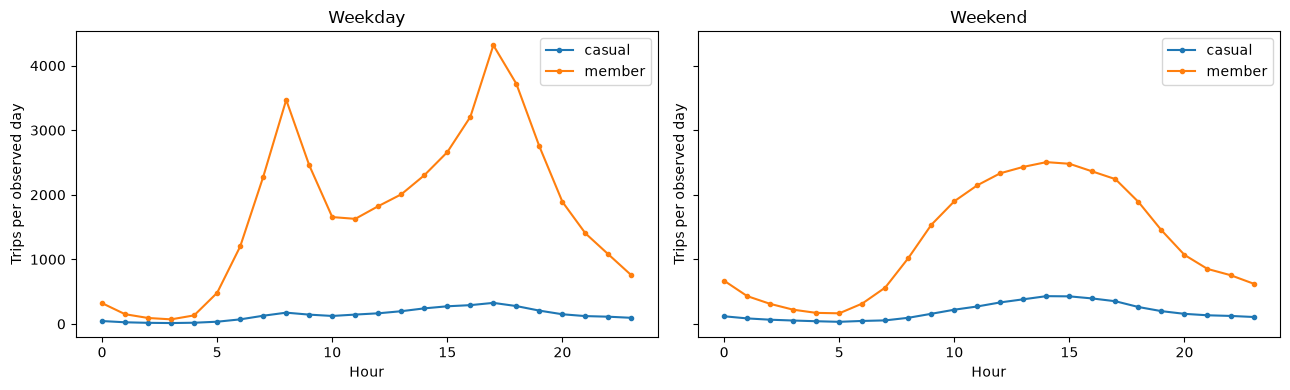

## Exercise 6 — Are electric bikes used differently?

Compare the count and median duration of each bike type, broken down by rider category. Then show how each bike type's **share of trips** changes through the day (not just its raw trip count).

size     median       mean
rideable_type member_casual                              
classic_bike  casual          19292  13.384258  30.479983
              member         311769   7.989500  14.363663
electric_bike casual          89335  10.073750  15.105336
              member         799048   7.823950  10.122103

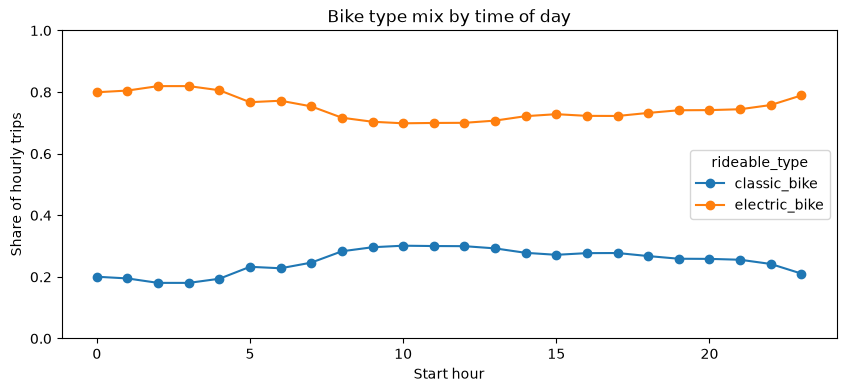

## Exercise 7 — Which stations are busiest?

Find the 20 stations with the most departures, arrivals, and total traffic. Compare rankings and discuss why a station might rank differently depending on the measure. Use **station IDs**, not names, as grouping keys.


Top 20 by departures


,station_name,departures
6140.05,W 21 St & 6 Ave,5412
6233.04,Pier 61 at Chelsea Piers,5408
5788.13,Lafayette St & E 8 St,4692
6331.01,W 31 St & 7 Ave,4478
6726.01,11 Ave & W 41 St,4350
6492.08,9 Ave & W 33 St,4223
5905.12,Broadway & E 14 St,3914
5779.11,Ave A & E 14 St,3820
5980.10,E 17 St & Broadway,3806
6756.01,W 43 St & 10 Ave,3677



Top 20 by arrivals


,station_name,arrivals
6233.04,Pier 61 at Chelsea Piers,5433
6140.05,W 21 St & 6 Ave,5400
5788.13,Lafayette St & E 8 St,4667
6331.01,W 31 St & 7 Ave,4454
6726.01,11 Ave & W 41 St,4364
6492.08,9 Ave & W 33 St,4184
5905.12,Broadway & E 14 St,3880
5980.10,E 17 St & Broadway,3868
5779.11,Ave A & E 14 St,3818
5374.01,Norfolk St & Broome St,3618



Top 20 by total


,station_name,total
6233.04,Pier 61 at Chelsea Piers,10841
6140.05,W 21 St & 6 Ave,10812
5788.13,Lafayette St & E 8 St,9359
6331.01,W 31 St & 7 Ave,8932
6726.01,11 Ave & W 41 St,8714
6492.08,9 Ave & W 33 St,8407
5905.12,Broadway & E 14 St,7794
5980.10,E 17 St & Broadway,7674
5779.11,Ave A & E 14 St,7638
6756.01,W 43 St & 10 Ave,7261


## Exercise 8 — Where do bikes accumulate?

Calculate each station's **net inflow** = arrivals minus departures, and list the ten largest gains and losses. Explain why these are not direct measurements of dock inventory or fleet redistribution.

Largest net gains:


,station_name,arrivals,departures,net_inflow
6364.1,6 Ave & W 34 St,984,0,984
5343.1,Allen St & Hester St,710,0,710
7154.1,3 Ave & E 82 St,703,0,703
7756.1,St Nicholas Ave & W 126 St,616,0,616
5997.1,W 12 St & Hudson St,461,0,461
5359.1,Hudson St & Reade St,405,0,405
6498.1,E 47 St & 2 Ave,326,0,326
6659.1,E 50 St & Park Ave,291,0,291
5755.01,Washington Pl & Broadway,1567,1408,159
5470.12,North Moore St & Greenwich St,2331,2233,98


Largest net losses:


,station_name,arrivals,departures,net_inflow
6364.10,6 Ave & W 34 St,1809,2822,-1013
7154.10,3 Ave & E 82 St,801,1506,-705
5343.10,Allen St & Hester St,1171,1813,-642
7756.10,St Nicholas Ave & W 126 St,620,1226,-606
5997.10,W 12 St & Hudson St,834,1301,-467
5359.10,Hudson St & Reade St,661,1069,-408
6659.10,E 50 St & Park Ave,487,845,-358
6498.10,E 47 St & 2 Ave,1411,1738,-327
6847.05,7 Ave & W 55 St,1360,1542,-182
6626.01,E 48 St & 5 Ave,1739,1904,-165


## Exercise 9 — What are the busiest routes?

Identify the top 20 ordered start → end station pairs and separately identify the top 10 routes for weekdays and weekends. **A→B and B→A are different routes.**

Top 20 overall


,start_station_id,end_station_id,trips
0,6104.01,6170.02,389
1,6170.02,6104.01,379
2,5944.01,6170.09,330
3,6170.09,5944.01,317
4,5294.04,5374.01,255
5,5902.07,6170.09,255
6,5379.10,5204.05,253
7,5204.05,5379.10,242
8,5374.01,5294.04,228
9,5379.10,5276.04,220


Weekdays


,start_station_id,end_station_id,trips
0,6170.02,6104.01,288
1,6104.01,6170.02,285
2,6170.09,5944.01,279
3,5944.01,6170.09,261
4,5216.07,5470.12,202
5,5379.10,5276.04,195
6,5379.10,5204.05,192
7,5294.04,5374.01,188
8,5902.07,6170.09,186
9,6331.01,6079.03,185


Weekends


,start_station_id,end_station_id,trips
0,6104.01,6170.02,104
1,6170.02,6104.01,91
2,6726.01,6602.05,79
3,5303.06,5294.04,75
4,6876.04,6876.04,72
5,5902.07,6170.09,69
6,5944.01,6170.09,69
7,5294.04,5374.01,67
8,5204.05,5379.10,66
9,5779.11,5545.01,62


## Exercise 10 — Do bikes return to their starting station?

What percent of trips have the same start and end station ID? Compare the proportions across member/casual riders and bike types. Exclude trips with unknown station IDs to avoid treating two missing values as a match.

Overall percentage: 1.6840482587015357


,member_casual,rideable_type,same_station_percent
0,casual,classic_bike,5.405123
1,casual,electric_bike,3.73387
2,member,classic_bike,1.793307
3,member,electric_bike,1.323284


## Exercise 11 — MAP: Where are the busiest stations?

Make an interactive map of the **100 stations with the most departures**. Scale marker sizes by departure count and color them by the percentage of departing riders who are casual. Add station names to hover labels. Describe any geographic clusters.

**Coordinate caution:** Trip files store trip endpoints, which may differ slightly from official dock coordinates. We approximate station coordinates using median trip start coordinates grouped by station ID. Invalid geographic coordinates are excluded.

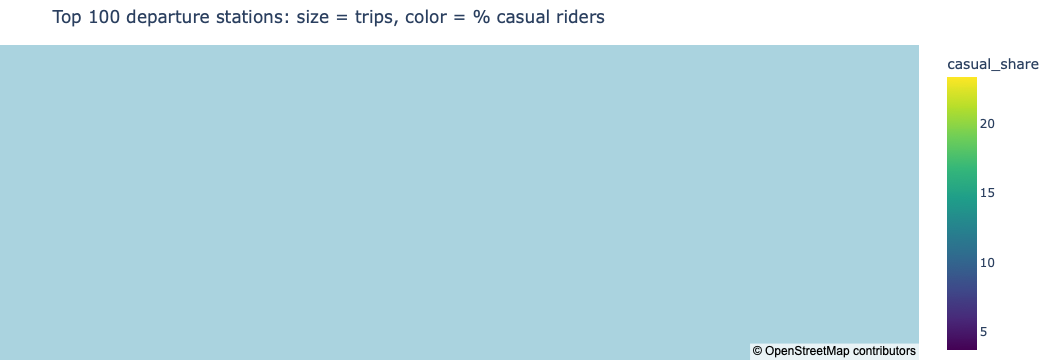

In [9]:
stations_geo = rides.dropna(subset=['start_station_id','start_lat','start_lng']).copy()
stations_geo = stations_geo[stations_geo.start_lat.between(40.3,41.2) &
                            stations_geo.start_lng.between(-74.5,-73.3)]
station_map = stations_geo.groupby('start_station_id').agg(
    station_name=('start_station_name','first'),
    lat=('start_lat','median'), lon=('start_lng','median'),
    departures=('ride_id','size'),
    casual_share=('member_casual', lambda x: 100*x.eq('casual').mean())
).reset_index()
top100 = station_map.nlargest(100,'departures')
fig = px.scatter_map(top100, lat='lat', lon='lon', size='departures',
    color='casual_share', hover_name='station_name', zoom=10,
    size_max=24, color_continuous_scale='Viridis',
    hover_data={'departures':True,'casual_share':':.1f','lat':False,'lon':False},
    title='Top 100 departure stations: size = trips, color = % casual riders')
fig.update_layout(map_style='open-street-map', margin=dict(l=0,r=0,t=45,b=0))
fig.show()

## Exercise 12 — MAP: Can station imbalances reveal redistribution needs?

For each station, calculate net inflow (arrivals minus departures) **during weekday mornings (7–10)** and **weekday evenings (16–19)**. Map the morning net inflow with diverging colors (net loss versus gain) and marker size proportional to absolute imbalance. Compare it to the evening map. Which stations reverse direction?

These metrics show observed trip flows only—not actual docking capacity, availability, or redistribution operations.

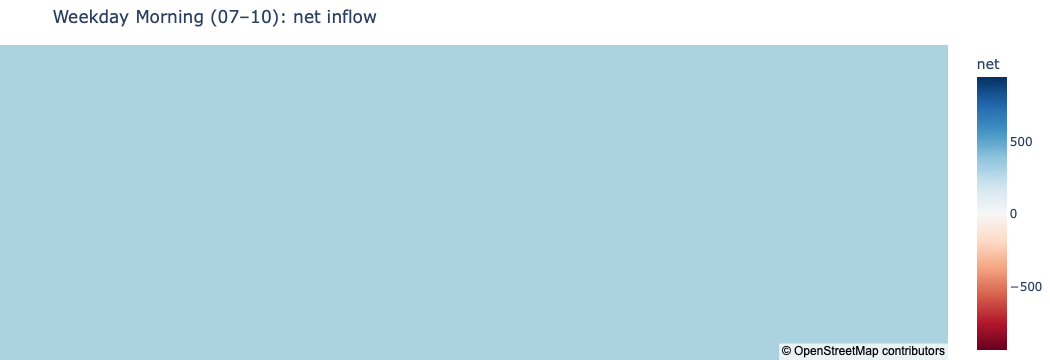

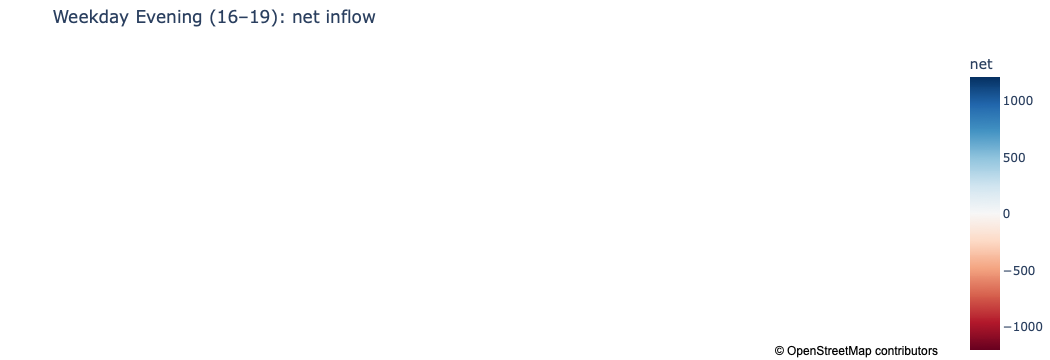

,morning_net,evening_net,combined_abs_flow
station_id,,,
5470.12,939.0,-1208.0,2147.0
6492.08,846.0,-868.0,1714.0
6584.12,772.0,-868.0,1640.0
6839.15,676.0,-641.0,1317.0
6756.01,-696.0,572.0,1268.0
6822.09,501.0,-691.0,1192.0
6740.10,514.0,-612.0,1126.0
6578.01,484.0,-577.0,1061.0
6064.08,516.0,-528.0,1044.0


In [21]:
# Create period-specific station flows, combining outbound and inbound station IDs.
weekdays = rides[~rides.is_weekend].copy()
windows = {'Morning (07–10)': (7,10), 'Evening (16–19)': (16,19)}
period_tables = {}
for label, (start_hour, stop_hour) in windows.items():
    part = weekdays[weekdays.hour.between(start_hour,stop_hour)]
    out = part.groupby('start_station_id').size().rename('out')
    inbound = part.groupby('end_station_id').size().rename('in')
    flow = pd.concat([out,inbound],axis=1).fillna(0)
    flow['net'] = flow['in'] - flow['out']
    flow.index.name = 'station_id'
    period_tables[label] = flow

map_coords = station_map.rename(columns={'start_station_id':'station_id'})
for label, flow in period_tables.items():
    m = map_coords.merge(flow[['net']], left_on='station_id', right_index=True, how='inner')
    m['abs_net'] = m.net.abs().clip(lower=1)
    fig = px.scatter_map(m, lat='lat', lon='lon', size='abs_net', color='net',
        hover_name='station_name', hover_data={'net':True,'abs_net':False,'lat':False,'lon':False},
        color_continuous_scale='RdBu', color_continuous_midpoint=0,
        size_max=23, zoom=10, title=f'Weekday {label}: net inflow')
    fig.update_layout(map_style='open-street-map',margin=dict(l=0,r=0,t=45,b=0))
    fig.show()

morning = period_tables['Morning (07–10)']['net'].rename('morning_net')
evening = period_tables['Evening (16–19)']['net'].rename('evening_net')
reversals = pd.concat([morning,evening],axis=1).dropna()
reversals = reversals[reversals.morning_net * reversals.evening_net < 0]
reversals['combined_abs_flow'] = reversals.morning_net.abs() + reversals.evening_net.abs()
display(reversals.nlargest(15,'combined_abs_flow'))

## Exercise 13 — How far do people travel? (Challenge)

Estimate each trip's **great-circle (straight-line) distance** using the Haversine formula, then compare distances and trip durations by bike type. Why isn't this an estimate of actual route mileage? How should same-station trips be interpreted?

In [22]:
distance_rides = rides.dropna(subset=['start_lat','start_lng','end_lat','end_lng']).copy()
distance_rides = distance_rides[
    distance_rides.start_lat.between(40.3,41.2) & distance_rides.end_lat.between(40.3,41.2) &
    distance_rides.start_lng.between(-74.5,-73.3) & distance_rides.end_lng.between(-74.5,-73.3)]
R = 6371.0  # Earth mean radius, km
lat1, lon1 = np.radians(distance_rides.start_lat), np.radians(distance_rides.start_lng)
lat2, lon2 = np.radians(distance_rides.end_lat), np.radians(distance_rides.end_lng)
dlat, dlon = lat2-lat1, lon2-lon1
a = np.sin(dlat/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
distance_rides['straight_km'] = 2*R*np.arcsin(np.sqrt(np.clip(a,0,1)))
display(distance_rides.groupby('rideable_type')[['straight_km','duration_min']].agg(['count','median','mean']))

straight_km                     duration_min            \
                    count    median      mean        count    median   
rideable_type                                                          
classic_bike       330375  1.106517  1.468127       330375  8.208750   
electric_bike      880152  1.442374  1.861856       880152  7.971708   

                          
                    mean  
rideable_type             
classic_bike   12.919436  
electric_bike  10.331486

## Exercise 14 — Which stations are commuter hubs? (Challenge)

Develop and explain a **commuter score** from weekday morning net departures, weekday evening net arrivals, and weekday-versus-weekend relative trip volume. Rank ten likely residential-origin commuter stations. This is a *heuristic*, not a validated commuter label.

In [23]:
morning_net = period_tables['Morning (07–10)']['net']
evening_net = period_tables['Evening (16–19)']['net']
# Positive is evidence of residence-side commuter behavior:
# bikes depart in the morning and arrive in the evening.
score = pd.DataFrame({'morning_net':morning_net,'evening_net':evening_net}).fillna(0)
# Weekday/weekend relative departure activity, adjusted for days observed.
by_period = rides.dropna(subset=['start_station_id']).groupby(['start_station_id','is_weekend']).size().unstack(fill_value=0)
for flag in [False, True]:
    if flag not in by_period.columns:
        by_period[flag] = 0
weekday_rate = by_period[False] / max(1,days_observed.get(False,0))
weekend_rate = by_period[True] / max(1,days_observed.get(True,0))
score['weekday_ratio'] = ((weekday_rate + 1) / (weekend_rate + 1)).reindex(score.index).fillna(1)
score['commuter_score'] = ((-score.morning_net).clip(lower=0) + score.evening_net.clip(lower=0)) * score.weekday_ratio.clip(upper=3)
score['station_name'] = station_names.reindex(score.index)
display(score.nlargest(10,'commuter_score')[['station_name','morning_net','evening_net','weekday_ratio','commuter_score']])

,station_name,morning_net,evening_net,weekday_ratio,commuter_score
station_id,,,,,
6756.01,W 43 St & 10 Ave,-696.0,572.0,1.382637,1753.184176
6602.03,W 41 St & 8 Ave,-233.0,421.0,2.570950,1681.401117
6726.01,11 Ave & W 41 St,-462.0,460.0,1.552591,1431.489329
5847.01,Christopher St & Greenwich St,-498.0,470.0,1.242237,1202.485263
6364.07,6 Ave & W 33 St,-230.0,430.0,1.766438,1165.849315
6765.01,12 Ave & W 40 St,-450.0,467.0,1.249523,1145.812500
6230.02,1 Ave & E 38 St,-232.0,195.0,2.518875,1075.559625
6331.01,W 31 St & 7 Ave,-279.0,227.0,2.032436,1028.412485
7059.08,West End Ave & W 60 St,-291.0,299.0,1.580471,932.477964


## Exercise 15 — Can we predict hourly station demand? (Challenge)

Choose the busiest departure station. Generate a continuous hourly time series (including zero-trip hours), then forecast the final 20% of hours using the **average from the same hour of week** in the training data. Compare against a naive constant-mean forecast using mean absolute error (MAE). This is a teaching baseline, not a deployment-grade predictor.

For strongest comparisons, use at least several weeks of unsampled data.

Station: W 21 St & 6 Ave
Hour-of-week MAE: 5.08
Constant mean MAE: 7.67


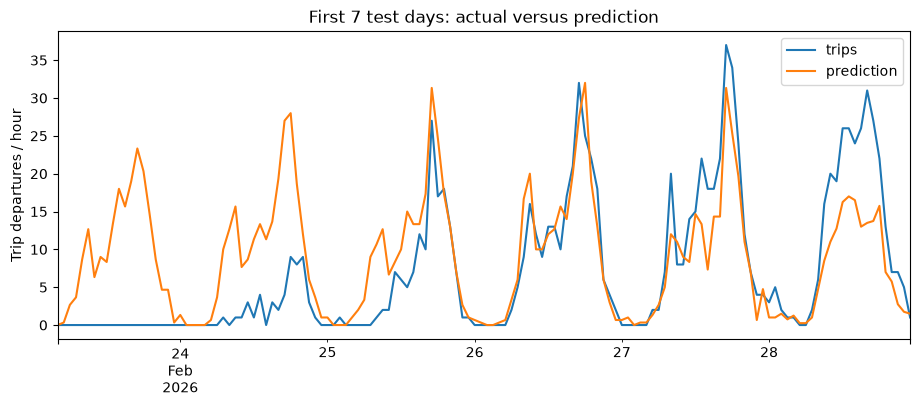

In [24]:
station_id = station_traffic.departures.idxmax()
s = rides.loc[rides.start_station_id.eq(station_id), 'started_at']
start = rides.started_at.min().floor('h')
stop = rides.started_at.max().floor('h')
hour_index = pd.date_range(start,stop,freq='h')
counts = s.dt.floor('h').value_counts().reindex(hour_index,fill_value=0).sort_index()
hour_df = pd.DataFrame({'trips':counts})
hour_df['hour_of_week'] = hour_df.index.dayofweek*24 + hour_df.index.hour
split = int(len(hour_df)*.8)
train, test = hour_df.iloc[:split].copy(), hour_df.iloc[split:].copy()
profile = train.groupby('hour_of_week').trips.mean()
test['prediction'] = test.hour_of_week.map(profile).fillna(train.trips.mean())
test['constant_baseline'] = train.trips.mean()
mae = lambda actual,pred: np.abs(actual-pred).mean()
print('Station:',station_names.get(station_id, station_id))
print('Hour-of-week MAE:', round(mae(test.trips,test.prediction),2))
print('Constant mean MAE:', round(mae(test.trips,test.constant_baseline),2))
test[['trips','prediction']].iloc[:24*7].plot(figsize=(11,4),title='First 7 test days: actual versus prediction')
plt.ylabel('Trip departures / hour'); plt.show()

## Exercise 16 — How concentrated is ridership? (Challenge)

Rank stations by departures, calculate what share of trips begins at the busiest **5%, 10%, and 20% of stations**, and plot the cumulative percentage of trips versus the cumulative percentage of stations. Discuss the operational implications of concentration.

Top 5% of stations (114): 25.3% of departures
Top 10% of stations (228): 41.5% of departures
Top 20% of stations (456): 63.9% of departures


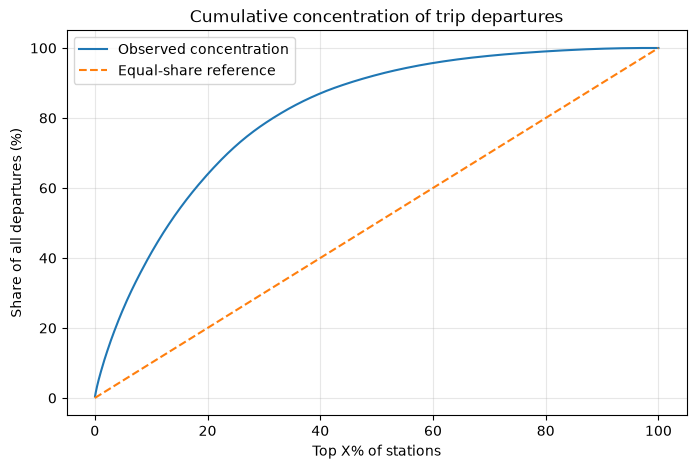

In [25]:
ordered = station_traffic.departures.sort_values(ascending=False)
n = len(ordered)
for p in [0.05,0.10,0.20]:
    top_n = max(1,int(np.ceil(n*p)))
    print(f'Top {p:.0%} of stations ({top_n}): {ordered.head(top_n).sum()/ordered.sum():.1%} of departures')
x = np.arange(1,n+1)/n * 100
y = ordered.cumsum().to_numpy()/ordered.sum()*100
plt.figure(figsize=(8,5)); plt.plot(x,y,label='Observed concentration')
plt.plot([0,100],[0,100],'--',label='Equal-share reference')
plt.xlabel('Top X% of stations'); plt.ylabel('Share of all departures (%)')
plt.title('Cumulative concentration of trip departures');plt.legend();plt.grid(alpha=.3);plt.show()

## Interpretation and limitations (all exercises)

For each exercise, submit a short interpretation alongside code/output. Address **missing station IDs**, **outlier durations**, **data period and sampling**, **station coordinate approximation**, and the distinction between **trip flows** and **actual dock inventory**. Straight-line distance is not traveled distance; peak trip counts are not proof of unmet demand. When comparing weekdays with weekends, normalize for observation period.

**Optional extension:** Repeat selected analyses with a second month and compare seasonal ridership patterns. Ensure months are ingested without double-counting archived and extracted copies.